
# Problem 2: Calibrating climate models

$\{Y(\theta): \theta \in [0,1]\}$ is a Gaussian process with $\mathrm E[Y(\theta)]=0.5$, $\mathrm{Var}[Y(\theta)]=0.5^2$ and correlation
$$
corr(\theta_1,\theta_2) = (1+15|\theta_1-\theta_2|)\,e^{-15|\theta_1-\theta_2|}
$$

This is a Matern type correlation function with $\phi = 15$

## 2a)

The conditional mean and covariance matrix is gien by
$$ 
\boldsymbol\mu_{A|B} = \boldsymbol\mu_A + \Sigma_{AB}\Sigma_{BB}^{-1}(\mathbf y_B-\boldsymbol\mu_B),\qquad
\Sigma_{A|B} = \Sigma_{AA} - \Sigma_{AB}\Sigma_{BB}^{-1}\Sigma_{BA}.
$$
The 90% prediction interval at $\theta_i$ is $\mu_{A|B,i} \pm z_{0.95}\sqrt{[\Sigma_{A|B}]_{ii}}$ with $z_{0.95}\approx 1.645$.

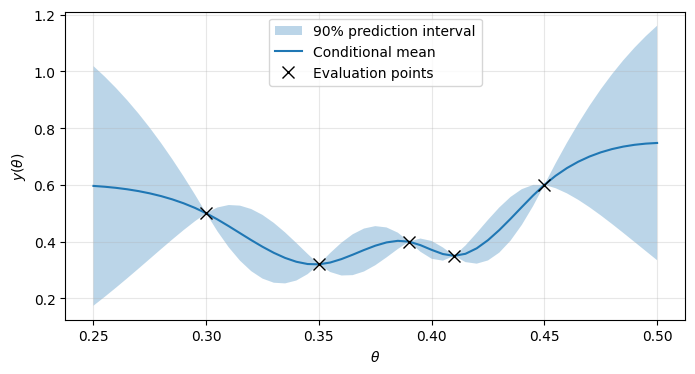

In [ ]:
import numpy as np
from scipy.stats import norm
import matplotlib.pyplot as plt

#PARAMETERS

theta_A = np.linspace(0.25, 0.5, 51) #Regular grid with spacing 0.005
theta_B = np.array([0.30, 0.35, 0.39, 0.41, 0.45]) #evaluation points
y_B = np.array([0.50, 0.32, 0.40 , 0.35, 0.60]) # observed values
var, phi = 0.5**2, 15   #Variance and phi(=15)
z = norm.ppf(0.95)      # 90% prediction interval
target = 0.30           #Target for task b) and c)  (Y(theta)<0.30)

#FUNCTIONS

def cov(t1, t2):  #Function for calculating the matern type covariance
    h = np.abs(np.subtract.outer(t1, t2))   #Distance matrix 
    return var * (1 + phi * h) * np.exp(-phi * h)

def gp_predict(theta_A, theta_B, y_B):

    ##### Calculates the conditional mean, lower and upper bounds for the prediction interval, probability for task b) and the conditional standard deviation
    
    mu_A = 0.5 * np.ones(len(theta_A))
    mu_B = 0.5 * np.ones(len(theta_B))

    #Covariance matrices:

    S_AA = cov(theta_A, theta_A)
    S_BB = cov(theta_B, theta_B)
    S_AB = cov(theta_A, theta_B)

    mu_cond = mu_A + S_AB @ np.linalg.solve(S_BB, y_B - mu_B)   # conditional mean
    s_cond  = S_AA - S_AB @ np.linalg.solve(S_BB, S_AB.T)       # conditional covariance

    sd = np.sqrt(np.clip(np.diag(s_cond), 0, None))   #Conditional standard deviation
    lower = mu_cond - z * sd  #Upper value in prediction interval
    upper = mu_cond + z * sd  #Lower value in prediction interval

    with np.errstate(divide="ignore"):  # sd = 0 at the evaluation points
        prob = norm.cdf((target - mu_cond) / sd)  #Probability for task b) and c)

    return mu_cond, sd, lower, upper, prob

mu_cond, sd, lower, upper, prob = gp_predict(theta_A, theta_B, y_B)

#Plotting conditional mean with evaluation points and 90% prediction interval

fig, ax = plt.subplots(figsize=(8, 4))
ax.fill_between(theta_A, lower, upper, alpha=0.3, label="90% prediction interval")
ax.plot(theta_A, mu_cond, label="Conditional mean")
ax.plot(theta_B, y_B, "kx", markersize=8, label="Evaluation points")
ax.set_xlabel(r"$\theta$")
ax.set_ylabel(r"$y(\theta)$")
ax.grid(True, alpha=0.3)
ax.legend()
plt.savefig("fig_2a.pdf", bbox_inches="tight")
plt.show()

Figure_ displays the prediction as a function of $\theta$, with the $90%$ prediction interval. We see that the conditional mean goes through all the evaluatin points, where the uncertanty is zero. We also observe that the prediction intervals becomes more uncertain at the edges, as theta is further from the evaluation points.

## 2b)

Marginally, $Y(\theta_i)\mid \mathbf y_B \sim \mathcal N(\mu_{A|B,i}, \sigma^2_{A|B,i})$, so
$$
P\big(Y(\theta_i)<0.30\mid \mathbf y_B\big) = \Phi\!\left(\frac{0.30-\mu_{A|B,i}}{\sigma_{A|B,i}}\right).
$$
At the evaluation points the standard deviation is zero and the probability is $0$ (all observed values exceed 0.30).

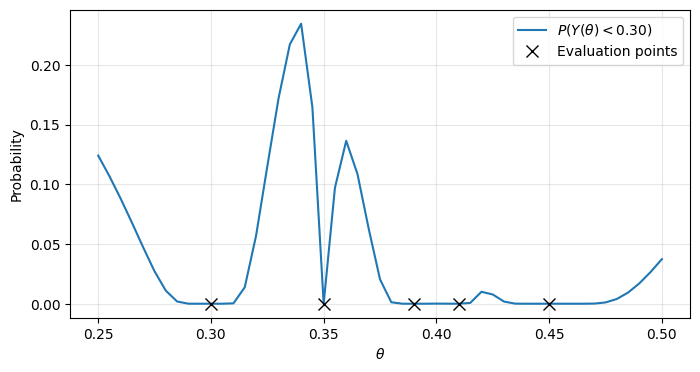

Max P = 0.235 at theta = 0.340


In [ ]:
#Plot task b). Probability that Y(theta < 0.30) with evaluation points

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(theta_A, prob, label=r"$P(Y(\theta) < 0.30)$")
ax.plot(theta_B, np.zeros_like(theta_B), "kx", markersize=8, label="Evaluation points")
ax.set_xlabel(r"$\theta$")
ax.set_ylabel("Probability")
ax.grid(True, alpha=0.3)
ax.legend()
plt.savefig("fig_2b.pdf", bbox_inches="tight")
plt.show()

#Highest probability with corresponding theta

i = np.argmax(prob)
print(f"Max P = {prob[i]:.3f} at theta = {theta_A[i]:.3f}")

## 2c) 

Figure_n shows the probability that $Y(\theta) < 0.30$. The probability is highest at $\theta = 0.340$ where the probability $P = 0.235$ The probability also grows at the edges, where the prediction is more uncertain.

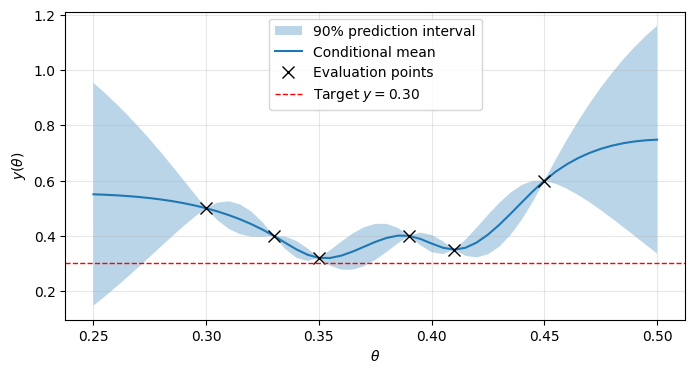

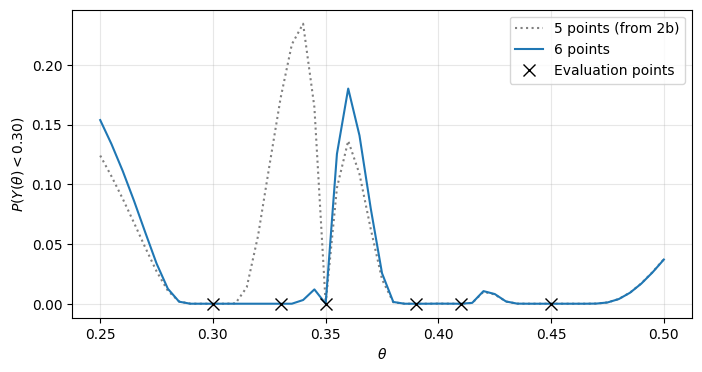

theta = 0.360  P = 0.180  mean = 0.328  sd = 0.031
theta = 0.250  P = 0.154  mean = 0.550  sd = 0.246
theta = 0.365  P = 0.141  mean = 0.343  sd = 0.040
theta = 0.255  P = 0.134  mean = 0.549  sd = 0.224
theta = 0.355  P = 0.125  mean = 0.320  sd = 0.017


In [36]:
#Adding the new evaluation point and calculating new prediction

theta_B6 = np.append(theta_B, 0.33)
y_B6     = np.append(y_B, 0.40)

mu_cond6, sd6, lower6, upper6, prob6 = gp_predict(theta_A, theta_B6, y_B6)

# Plot of prediction with 6 points
fig, ax = plt.subplots(figsize=(8, 4))
ax.fill_between(theta_A, lower6, upper6, alpha=0.3, label="90% prediction interval")
ax.plot(theta_A, mu_cond6, label="Conditional mean")
ax.plot(theta_B6, y_B6, "kx", markersize=8, label="Evaluation points")
ax.axhline(target, ls="--", color="red", lw=1, label="Target $y = 0.30$")
ax.set_xlabel(r"$\theta$")
ax.set_ylabel(r"$y(\theta)$")
ax.grid(True, alpha=0.3)
ax.legend()
plt.savefig("fig_2c_pred.pdf", bbox_inches="tight")
plt.show()

# Probability with 6 points, compared with 5 points from 2b
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(theta_A, prob, ":", color="gray", label="5 points (from 2b)")
ax.plot(theta_A, prob6, label="6 points")
ax.plot(theta_B6, np.zeros_like(theta_B6), "kx", markersize=8, label="Evaluation points")
ax.set_xlabel(r"$\theta$")
ax.set_ylabel(r"$P(Y(\theta) < 0.30)$")
ax.grid(True, alpha=0.3)
ax.legend()
plt.savefig("fig_2c_prob.pdf", bbox_inches="tight")
plt.show()

# Candidates for the last model run
for i in np.argsort(prob6)[::-1][:5]:
    print(f"theta = {theta_A[i]:.3f}  P = {prob6[i]:.3f}  "
          f"mean = {mu_cond6[i]:.3f}  sd = {sd6[i]:.3f}")

With a new evaluation point $(\theta = 0.33, y(\theta) = 0.40)$ added to the set of oberved values, the predicion changes. Figure_ shows the new predicion interval togheter with the conditional mean, and the target value. The new value erases the highets probability form $b)$ at $\theta = 0.340$, as illustrated in figure_n which includes both the probability with 5 and 6 points. This is because the new value is high compared to the target, and therefore pulls the predicted mean up, and also reduces the uncertainty.

Calculating the highest probabilities, we see that the highest probability, and highest chance to achive $\theta < 0.30$ is for $theta = 0.36$ with probability $P = 0.180$.. This value has a low mean and corresponding sstandard deviation compared to the teta with second highest probability. The third best also has a low mean and standard deviation, but a lower probability of achieving the target value. We would therefore suggest that the scientist use $\theta = 0.36$.

